# 92104 North Park: Building Footprints

Run `python src/data/fetch_osm.py --zip 92104` from the repo root first. That saves the footprints to `data/raw/` in UTM 11N (EPSG:32611), so all distances below are in meters.

## Load Footprints

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import duckdb
from pathlib import Path

ZIP = "92104"
RAW = Path("../../data/raw")

gdf = gpd.read_parquet(RAW / f"osm_buildings_{ZIP}.parquet")
zcta = gpd.read_parquet(RAW / f"zcta_{ZIP}.parquet")
print("CRS: EPSG", gdf.crs.to_epsg())
print("Buildings:", len(gdf))

/opt/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


CRS: EPSG 32611
Buildings: 10826


In [2]:
# Lawrence asked for GeoPackage, so also save a .gpkg copy (data/ is gitignored)
gdf.to_file(RAW / f"osm_buildings_{ZIP}.gpkg", layer="buildings", driver="GPKG")

## Mapping and Visualizing Footprints

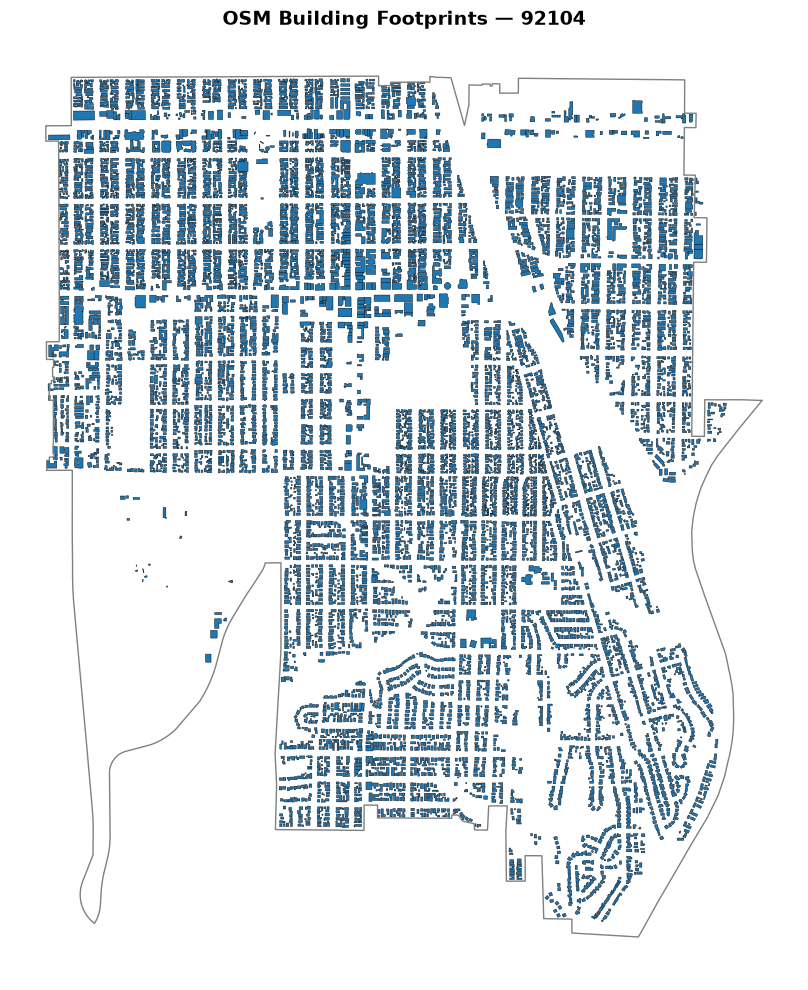

In [3]:
fig, ax = plt.subplots(figsize=(10, 10))
zcta.boundary.plot(ax=ax, color="gray", linewidth=1)
gdf.plot(ax=ax, edgecolor="black", linewidth=0.3)
ax.set_title(f"OSM Building Footprints — {ZIP}", fontsize=14, fontweight="bold")
ax.set_axis_off()
plt.tight_layout()
plt.show()

## Transformations

#### Shift All Buildings East By 5 m

This simulates a location error: every footprint is moved 5 m east with DuckDB's `ST_Translate(geom, dx, dy)`. Because the data is in UTM, `dx = 5` means 5 meters.

In [4]:
con = duckdb.connect()
con.execute("INSTALL spatial; LOAD spatial;")

# Hand the footprints to DuckDB as WKB, then turn them back into geometries
df = gdf[["id", "geometry"]].copy()
df["wkb"] = df.geometry.to_wkb()
df = df.drop(columns="geometry")
con.register("df", df)
con.execute("CREATE TABLE buildings AS SELECT id, ST_GeomFromWKB(wkb) AS geom FROM df")

SHIFT_M = 5
con.execute(f"""
    CREATE TABLE shifted AS
    SELECT id, ST_Translate(geom, {SHIFT_M}, 0) AS geom
    FROM buildings
""")

In [5]:
# Sanity check: every centroid should move exactly 5 m
lo, hi = con.execute("""
    SELECT MIN(ST_Distance(ST_Centroid(b.geom), ST_Centroid(s.geom))),
           MAX(ST_Distance(ST_Centroid(b.geom), ST_Centroid(s.geom)))
    FROM buildings b JOIN shifted s USING (id)
""").fetchone()
print(f"Centroid shift: min {lo:.2f} m, max {hi:.2f} m")

Centroid shift: min 5.00 m, max 5.00 m


In [6]:
# Back to GeoPandas for plotting
shifted = con.execute("SELECT id, ST_AsWKB(geom) AS wkb FROM shifted").df()
gdf_shift = gpd.GeoDataFrame(
    shifted[["id"]], geometry=gpd.GeoSeries.from_wkb(shifted["wkb"].apply(bytes)), crs=gdf.crs
)

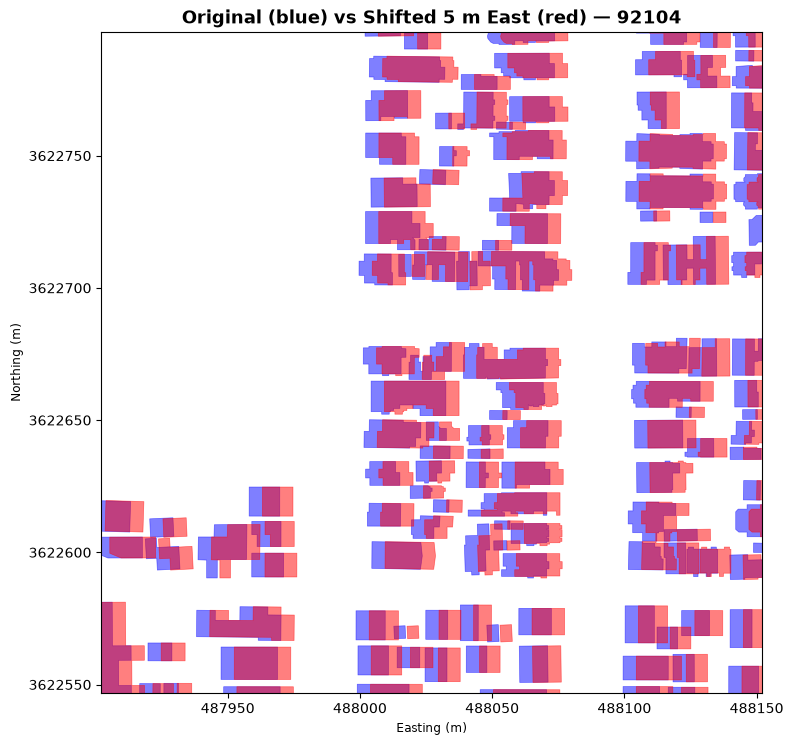

In [7]:
# Zoom into a 250 m window around a building in the middle of the zip,
# because at full-zip scale a 5 m shift is invisible
near = gdf.distance(zcta.geometry.iloc[0].centroid).idxmin()
cx, cy = gdf.loc[near].geometry.centroid.coords[0]
half = 125

fig, ax = plt.subplots(figsize=(8, 8))
gdf.plot(ax=ax, color="blue", alpha=0.5, edgecolor="blue", linewidth=0.5)
gdf_shift.plot(ax=ax, color="red", alpha=0.5, edgecolor="red", linewidth=0.5)
ax.set_xlim(cx - half, cx + half)
ax.set_ylim(cy - half, cy + half)
ax.ticklabel_format(useOffset=False, style="plain")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_title(f"Original (blue) vs Shifted 5 m East (red) — {ZIP}", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

Purple is where the original and shifted footprints still overlap. The red strip on the east side of each building and the blue strip on the west side are the 5 m that moved. Buildings that are less than 5 m apart now overlap their neighbor, which is the kind of error a geocoding or imagery offset can create in real data.